In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch 
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader , TensorDataset, random_split

In [2]:
X = np.array([[-1.58986e-01,  4.23977e-01],
       [-3.47926e-01,  4.70760e-01],
       [-5.04608e-01,  3.53801e-01],
       [-5.96774e-01,  1.14035e-01],
       [-5.18433e-01, -1.72515e-01],
       [-2.92627e-01, -2.07602e-01],
       [-1.58986e-01, -4.38596e-02],
       [-5.76037e-02,  1.43275e-01],
       [-7.14286e-02,  2.71930e-01],
       [-2.97235e-01,  3.47953e-01],
       [-4.17051e-01,  2.01754e-01],
       [-4.40092e-01,  8.77193e-03],
       [-3.24885e-01, -3.21637e-02],
       [-2.46544e-01,  5.55556e-02],
       [-2.18894e-01,  2.01754e-01],
       [-3.43318e-01,  1.60819e-01],
       [-5.09217e-01,  7.89474e-02],
       [-3.84793e-01, -9.06433e-02],
       [-1.49770e-01,  1.25731e-01],
       [-1.95853e-01,  3.24561e-01],
       [-3.91705e-02, -2.19298e-01],
       [-1.08295e-01, -3.01170e-01],
       [-1.86636e-01, -3.30409e-01],
       [-2.18894e-01, -4.23977e-01],
       [-8.06452e-02, -5.64327e-01],
       [ 6.68203e-02, -5.17544e-01],
       [ 9.44700e-02, -3.24561e-01],
       [ 1.86636e-01, -1.66667e-01],
       [ 6.22120e-02, -7.30994e-02],
       [ 2.07373e-02, -1.95906e-01],
       [ 2.99539e-02, -3.42105e-01],
       [-9.90783e-02, -3.77193e-01],
       [-6.91244e-03, -4.64912e-01],
       [ 1.31336e-01, -4.29825e-01],
       [ 2.32719e-01, -1.95906e-01],
       [ 8.52535e-02, -8.47953e-02],
       [-1.31336e-01, -2.36842e-01],
       [ 2.30415e-03, -1.25731e-01],
       [ 1.22120e-01, -2.92398e-03],
       [-3.47926e-01, -3.12865e-01],
       [-2.28111e-01, -1.25731e-01],
       [-7.60369e-02,  1.46199e-02],
       [ 4.37788e-02,  2.04678e-02],
       [ 1.15207e-02,  1.54971e-01],
       [-4.17051e-01, -1.60819e-01],
       [-3.15668e-01, -3.18713e-01],
       [ 1.26728e-01, -2.19298e-01],
       [ 2.05069e-01, -3.12865e-01],
       [ 2.18894e-01, -4.59064e-01],
       [ 7.14286e-02, -6.46199e-01],
       [-1.31336e-01, -6.05263e-01],
       [-2.09677e-01, -5.81871e-01],
       [-2.28111e-01, -4.29825e-01],
       [-1.45161e-01, -4.12281e-01],
       [-6.68203e-02, -4.82456e-01],
       [ 1.35945e-01, -5.11696e-01],
       [ 2.69585e-01, -4.06433e-01],
       [ 2.97235e-01, -2.95322e-01],
       [ 2.74194e-01, -1.72515e-01],
       [ 2.55760e-01, -4.97076e-02],
       [ 2.23502e-01, -4.97076e-02],
       [ 1.82028e-01, -8.47953e-02],
       [ 1.58986e-01, -1.54971e-01],
       [ 7.14286e-02, -2.13450e-01],
       [ 1.61290e-02, -2.66082e-01],
       [-2.53456e-02, -3.83041e-01],
       [-1.15207e-02, -4.82456e-01],
       [-2.30415e-03, -5.05848e-01],
       [ 2.53456e-02, -5.11696e-01],
       [ 2.53456e-02, -5.58480e-01],
       [ 1.15207e-02, -6.57895e-01],
       [-4.83871e-02, -6.46199e-01],
       [-8.52535e-02, -5.52632e-01],
       [-9.90783e-02, -5.00000e-01],
       [-1.61290e-02, -4.23977e-01],
       [ 1.31336e-01, -3.59649e-01],
       [ 2.23502e-01, -3.71345e-01],
       [ 2.92627e-01, -3.01170e-01],
       [ 2.60369e-01, -2.07602e-01],
       [ 2.00461e-01, -2.25146e-01],
       [ 1.72811e-01, -2.71930e-01],
       [-1.31336e-01,  9.06433e-02],
       [-1.49770e-01,  7.30994e-02],
       [-2.41935e-01,  6.14035e-02],
       [-3.01843e-01,  1.78363e-01],
       [-2.97235e-01,  1.95906e-01],
       [-2.74194e-01,  3.07018e-01],
       [-3.24885e-01,  2.95322e-01],
       [-3.98618e-01,  2.66082e-01],
       [-4.35484e-01,  1.60819e-01],
       [-4.72350e-01,  7.89474e-02],
       [-3.38710e-01,  4.38596e-02],
       [-2.69585e-01,  4.38596e-02],
       [-2.55760e-01,  1.02339e-01],
       [-1.68203e-01,  2.66082e-01],
       [-1.12903e-01,  3.01170e-01],
       [-3.91705e-02,  3.47953e-01],
       [-1.26728e-01,  4.41520e-01],
       [-2.32719e-01,  4.41520e-01],
       [-3.38710e-01,  4.18129e-01],
       [-4.12442e-01,  3.53801e-01],
       [-5.09217e-01,  2.19298e-01],
       [-5.41475e-01,  1.46199e-02],
       [-5.04608e-01, -1.25731e-01],
       [-4.90783e-01, -1.43275e-01],
       [-3.61751e-01, -1.37427e-01],
       [-2.69585e-01, -8.47953e-02],
       [-2.23502e-01, -7.89474e-02],
       [-1.86636e-01, -3.80117e-02],
       [-1.54378e-01, -8.77193e-03],
       [-1.12903e-01,  5.55556e-02],
       [-8.52535e-02,  1.37427e-01],
       [-8.52535e-02,  2.77778e-01],
       [-1.68203e-01,  3.01170e-01],
       [-1.91244e-01,  1.95906e-01],
       [-1.40553e-01, -4.97076e-02],
       [-2.99539e-02,  6.72515e-02],
       [-2.00461e-01, -2.30994e-01],
       [-1.08295e-01, -8.47953e-02],
       [ 3.45622e-02,  6.72515e-02],
       [ 8.06452e-02,  1.19883e-01],
       [-3.85369e-01,  3.30409e-02],
       [-3.81221e-01,  1.31287e-01],
       [-3.52189e-01,  2.58187e-01],
       [-3.54263e-01,  3.64620e-01],
       [-4.14401e-01, -6.92982e-02],
       [-4.99424e-01, -3.24561e-02],
       [-2.98272e-01, -9.79532e-02],
       [-3.16935e-01, -1.83918e-01],
       [-3.68779e-01, -2.90351e-01],
       [-3.56336e-01, -3.96784e-01],
       [-2.71313e-01,  4.38596e-03],
       [-1.77995e-01,  8.62573e-02],
       [-2.46429e-01,  1.43567e-01],
       [-2.50576e-01,  2.29532e-01],
       [-2.21544e-01,  3.76901e-01],
       [-2.15323e-01,  2.95029e-01],
       [-1.30300e-01,  2.17251e-01],
       [-2.07028e-01,  2.89474e-02],
       [-9.71198e-02,  2.13158e-01],
       [-3.90553e-02,  2.58187e-01],
       [ 1.90092e-02,  4.01462e-01],
       [-3.69816e-02,  4.21930e-01],
       [-6.39401e-02,  3.31871e-01],
       [-1.30300e-01,  3.76901e-01],
       [-3.75000e-01, -4.37719e-01],
       [-3.95737e-01, -3.51754e-01],
       [-3.54263e-01, -2.08480e-01],
       [-4.37212e-01, -3.76316e-01],
       [-4.80760e-01, -5.03216e-01],
       [-4.10253e-01, -4.66374e-01],
       [-2.48502e-01, -2.57602e-01],
       [-2.27765e-01, -3.14912e-01],
       [-2.83756e-01, -3.84503e-01],
       [-2.92051e-01, -4.54094e-01],
       [-3.37673e-01, -5.19591e-01],
       [-2.77535e-01, -5.48246e-01],
       [-2.07028e-01, -5.35965e-01],
       [-1.86290e-01, -4.78655e-01],
       [-1.32373e-01, -5.07310e-01],
       [-1.77995e-01, -2.98538e-01],
       [-1.65553e-01, -1.75731e-01],
       [-1.61406e-01, -1.26608e-01],
       [ 3.45622e-04,  2.58187e-01],
       [ 7.91475e-02,  3.56433e-01],
       [-2.66129e-02,  1.80409e-01],
       [-5.35714e-02,  7.80702e-02],
       [-1.41705e-02, -5.29240e-02],
       [-7.01613e-02, -1.63450e-01],
       [-6.39401e-02, -2.94444e-01],
       [-3.07604e-02, -4.66374e-01],
       [-5.77189e-02, -5.27778e-01],
       [-5.35714e-02, -3.96784e-01],
       [ 5.21889e-02, -4.17251e-01],
       [-1.62442e-02, -1.67544e-01],
       [-6.39401e-02, -8.56725e-02],
       [-6.18664e-02, -1.60819e-02],
       [-3.80184e-03,  4.38596e-03],
       [ 4.18203e-02,  2.04971e-01],
       [ 7.91475e-02,  1.92690e-01],
       [ 4.59677e-02,  2.54094e-01],
       [ 1.18548e-01,  1.92690e-01],
       [ 1.10253e-01,  8.62573e-02],
       [ 1.08180e-01, -6.92982e-02],
       [ 1.66244e-01, -2.42690e-02],
       [ 1.41359e-01,  6.57895e-02],
       [ 1.43433e-01,  1.68129e-01],
       [ 1.70392e-01,  1.92690e-01],
       [ 1.08180e-01,  2.99123e-01],
       [ 1.18548e-01,  3.19591e-01],
       [ 1.26843e-01,  3.93275e-01],
       [-8.67512e-02,  4.21930e-01],
       [-4.73502e-02,  5.07895e-01],
       [ 2.52304e-02,  5.20175e-01],
       [ 6.25576e-02,  5.52924e-01],
       [-5.87558e-03,  4.42398e-01],
       [-5.14977e-02,  5.73392e-01],
       [-8.05300e-02,  5.07895e-01],
       [-1.53111e-01,  5.52924e-01],
       [-1.11636e-01,  5.48830e-01],
       [-1.63479e-01,  4.91520e-01],
       [-2.52650e-01, -1.88012e-01],
       [-2.46429e-01, -3.65497e-02],
       [-3.21083e-01, -4.33626e-01],
       [-3.31452e-01, -6.05556e-01],
       [-3.85369e-01, -5.15497e-01],
       [-3.99885e-01, -6.21930e-01],
       [-1.24078e-01, -1.26608e-01],
       [-3.16935e-01, -2.28947e-01],
       [-2.94124e-01, -1.34795e-01],
       [-1.53111e-01,  1.84503e-01]])


In [3]:
y = np.array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 1., 1., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 0., 0.,
       0., 0., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       0., 1., 1., 1., 1., 0., 0.])


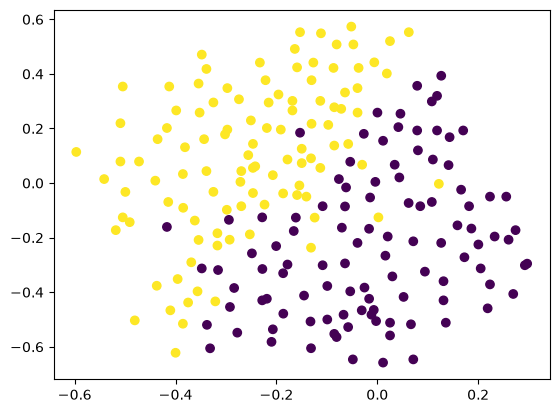

In [4]:
# scatter plot visualization
plt.scatter(X[:,0], X[:,1], c=y)
plt.show()


In [5]:
class DeepClassificationNetwork(nn.Module):
    def __init__(self, use_dropout=False):
        super(DeepClassificationNetwork,self).__init__()
        self.use_dropout=use_dropout
        self.fc1 = nn.Linear(2, 128)
        self.relu1 = nn.ReLU()
        self.drop1 = nn.Dropout(0.5)
        
        self.fc2 = nn.Linear(128, 128)
        self.relu2 = nn.ReLU()
        self.drop2 = nn.Dropout(0.5)
        
        self.out = nn.Linear(128, 1)
        self.sigmoid = nn.Sigmoid()
    def forward(self,x):
        x = self.fc1(x)
        x = self.relu1(x)
        if self.use_dropout:
            x = self.drop1(x)
            
        x = self.fc2(x)
        x = self.relu2(x)
        if self.use_dropout:
            x = self.drop2(x)
            
        x = self.out(x)
        x = self.sigmoid(x)
        return x



In [6]:
# Convert numpy configurations to target floating PyTorch Tensors
X_tensor = torch.tensor(X, dtype=torch.float32)
y_tensor = torch.tensor(y, dtype=torch.float32).unsqueeze(1)

# Generate explicit train/validation subsets (80/20 split)
dataset = TensorDataset(X_tensor, y_tensor)
val_size = int(0.2 * len(dataset))
train_size = len(dataset) - val_size

torch.manual_seed(42) # Anchor tracking distribution
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

# Initialize standard mini-batch pipelines (defaulting to batch size 32)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

# Initialize standard network (Dropout off for initialization baseline match)
model = DeepClassificationNetwork(use_dropout=False)
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

# Training History Containers
history = {'loss': [], 'val_loss': [], 'accuracy': [], 'val_accuracy': []}

epochs = 500
for epoch in range(epochs):
    # --- TRAINING STAGE ---
    model.train()
    train_loss, train_correct, total_train = 0.0, 0, 0
    
    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item() * batch_X.size(0)
        predictions = (outputs >= 0.5).float()
        train_correct += (predictions == batch_y).sum().item()
        total_train += batch_y.size(0)
        
    epoch_loss = train_loss / total_train
    epoch_acc = train_correct / total_train
    
    # --- VALIDATION STAGE ---
    model.eval()
    val_loss, val_correct, total_val = 0.0, 0, 0
    
    with torch.no_grad():
        for batch_X, batch_y in val_loader:
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            
            val_loss += loss.item() * batch_X.size(0)
            predictions = (outputs >= 0.5).float()
            val_correct += (predictions == batch_y).sum().item()
            total_val += batch_y.size(0)
            
    epoch_val_loss = val_loss / total_val
    epoch_val_acc = val_correct / total_val
    
    # Update logs
    history['loss'].append(epoch_loss)
    history['val_loss'].append(epoch_val_loss)
    history['accuracy'].append(epoch_acc)
    history['val_accuracy'].append(epoch_val_acc)
    
    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch {epoch+1:3d}/{epochs} - loss: {epoch_loss:.4f} - accuracy: {epoch_acc:.4f} - val_loss: {epoch_val_loss:.4f} - val_accuracy: {epoch_val_acc:.4f}")


Epoch   1/500 - loss: 0.5740 - accuracy: 0.7278 - val_loss: 0.3322 - val_accuracy: 0.8571
Epoch  10/500 - loss: 0.2337 - accuracy: 0.9290 - val_loss: 0.1975 - val_accuracy: 0.8571
Epoch  20/500 - loss: 0.2509 - accuracy: 0.8817 - val_loss: 0.1654 - val_accuracy: 0.9048
Epoch  30/500 - loss: 0.2464 - accuracy: 0.8935 - val_loss: 0.1535 - val_accuracy: 0.9286
Epoch  40/500 - loss: 0.2029 - accuracy: 0.9408 - val_loss: 0.1742 - val_accuracy: 0.9286
Epoch  50/500 - loss: 0.1957 - accuracy: 0.9467 - val_loss: 0.1703 - val_accuracy: 0.9286
Epoch  60/500 - loss: 0.1894 - accuracy: 0.9467 - val_loss: 0.1568 - val_accuracy: 0.9286
Epoch  70/500 - loss: 0.2517 - accuracy: 0.8757 - val_loss: 0.1970 - val_accuracy: 0.9286
Epoch  80/500 - loss: 0.1666 - accuracy: 0.9467 - val_loss: 0.1503 - val_accuracy: 0.9048
Epoch  90/500 - loss: 0.1703 - accuracy: 0.9349 - val_loss: 0.1392 - val_accuracy: 0.9286
Epoch 100/500 - loss: 0.1691 - accuracy: 0.9349 - val_loss: 0.1913 - val_accuracy: 0.9286
Epoch 110/

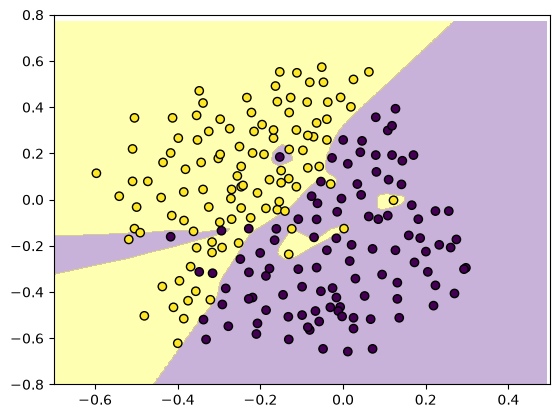

In [7]:
def draw_decision_surface(X, y, model_instance):
    model_instance.eval()
    x_min, x_max = X[:, 0].min() - 0.2, X[:, 0].max() + 0.2
    y_min, y_max = X[:, 1].min() - 0.2, X[:, 1].max() + 0.2
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01), np.arange(y_min, y_max, 0.01))
    
    grid_points = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)
    with torch.no_grad():
        predictions = model_instance(grid_points).reshape(xx.shape).numpy()
        
    plt.contourf(xx, yy, predictions, levels=[0, 0.5, 1], alpha=0.3, colors=['#4b0082', '#ffff00'])
    plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k')

draw_decision_surface(X, y, model)
plt.xlim(-0.7, 0.5)
plt.ylim(-0.8, 0.8)
plt.show()


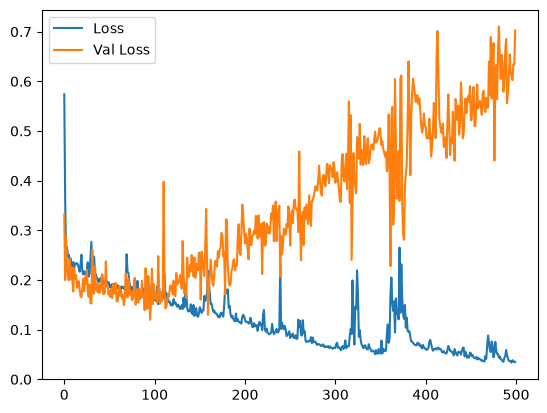

In [8]:
plt.plot(history['loss'], label='Loss')
plt.plot(history['val_loss'], label='Val Loss')
plt.legend()
plt.show()


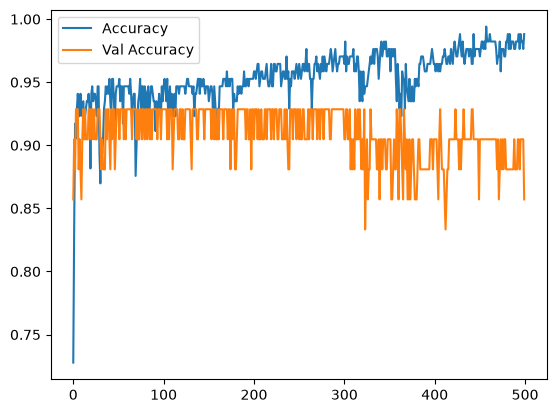

In [9]:
plt.plot(history['accuracy'], label='Accuracy')
plt.plot(history['val_accuracy'], label='Val Accuracy')
plt.legend()
plt.show()


In [10]:
# Initialize a fresh configuration containing initialized dropout components
dropout_model = DeepClassificationNetwork(use_dropout=True)
optimizer = optim.Adam(dropout_model.parameters(), lr=0.01)

dropout_history = {'loss': [], 'val_loss': [], 'accuracy': [], 'val_accuracy': []}

for epoch in range(epochs):
    # --- TRAINING STAGE ---
    dropout_model.train()
    train_loss, train_correct, total_train = 0.0, 0, 0
    
    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()
        outputs = dropout_model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item() * batch_X.size(0)
        predictions = (outputs >= 0.5).float()
        train_correct += (predictions == batch_y).sum().item()
        total_train += batch_y.size(0)
        
    epoch_loss = train_loss / total_train
    epoch_acc = train_correct / total_train
    
    # --- VALIDATION STAGE ---
    dropout_model.eval()
    val_loss, val_correct, total_val = 0.0, 0, 0
    
    with torch.no_grad():
        for batch_X, batch_y in val_loader:
            outputs = dropout_model(batch_X)
            loss = criterion(outputs, batch_y)
            
            val_loss += loss.item() * batch_X.size(0)
            predictions = (outputs >= 0.5).float()
            val_correct += (predictions == batch_y).sum().item()
            total_val += batch_y.size(0)
            
    epoch_val_loss = val_loss / total_val
    epoch_val_acc = val_correct / total_val
    
    # Update logs
    dropout_history['loss'].append(epoch_loss)
    dropout_history['val_loss'].append(epoch_val_loss)
    dropout_history['accuracy'].append(epoch_acc)
    dropout_history['val_accuracy'].append(epoch_val_acc)


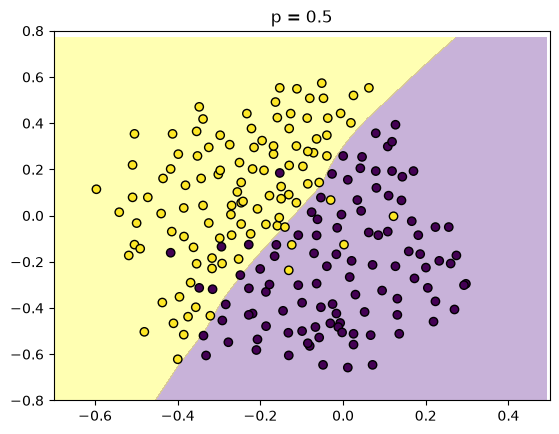

In [11]:
draw_decision_surface(X, y, dropout_model)
plt.xlim(-0.7, 0.5)
plt.ylim(-0.8, 0.8)
plt.title('p = 0.5')
plt.show()
